# Customer Sentiment and Churn Prediction: NLP Integration

A financial organization wants to improve its churn prediction system by adding customer sentiment, extracted from free-text feedback, to the structured customer attributes it already models. This notebook builds an NLP sentiment pipeline over `Customer_Feedback.csv`, then merges the sentiment output with `Churn_Modeling.csv` on `CustomerId` and checks whether sentiment improves churn prediction.

| Task | Section |
|---|---|
| 1 | Data loading and exploration |
| 2 | Text cleaning and preprocessing (normalize, tokenize, stopwords, lemmatize) |
| 3 | Sentiment labeling (star ratings, VADER, TextBlob, optional pre-trained model) |
| 4 | Text vectorization (Bag-of-Words, TF-IDF, optional sentence embeddings) |
| 5 | Model development and evaluation (Logistic Regression, Linear SVM, Naive Bayes, BiLSTM) |
| 6 | Integration with the churn dataset, plus a churn model with and without sentiment |
| 7 | Visualization and insights |

**Before running:** put both CSVs in the `data/` folder next to this notebook. Column names for the feedback file are detected automatically (ID, text, and star rating); if detection picks the wrong column, set the overrides in the configuration cell.

## Setup

In [1]:
import os
import re
import string
import warnings
from collections import Counter
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from IPython.display import display
from matplotlib.patches import Patch

import nltk
from nltk.corpus import stopwords, wordnet
from nltk.stem import WordNetLemmatizer
from nltk.tokenize import word_tokenize
from nltk.sentiment import SentimentIntensityAnalyzer
from textblob import TextBlob
from wordcloud import WordCloud

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, classification_report, cohen_kappa_score,
                             confusion_matrix, f1_score, precision_score, recall_score,
                             ConfusionMatrixDisplay)
from sklearn.model_selection import (StratifiedKFold, cross_val_predict, cross_val_score,
                                     cross_validate, train_test_split)
from sklearn.naive_bayes import MultinomialNB
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.svm import LinearSVC
from sklearn.utils.class_weight import compute_class_weight

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 140)

### Configuration

In [2]:
# ---- Paths ----
DATA_DIR = Path("data")
CHURN_FILE = DATA_DIR / "Churn_Modeling.csv"
FEEDBACK_FILE = DATA_DIR / "Customer_Feedback.csv"
OUT_DIR = Path("outputs")
FIG_DIR = OUT_DIR / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

RANDOM_STATE = 42
TEST_SIZE = 0.20

# ---- Column overrides (leave as None to auto-detect) ----
ID_COL_OVERRIDE = None        # e.g. "CustomerId"
TEXT_COL_OVERRIDE = None      # e.g. "Feedback"
RATING_COL_OVERRIDE = None    # e.g. "Rating"; set to False to ignore ratings entirely

# ---- Sentiment labeling ----
# "auto" uses star ratings when the file has them, otherwise VADER.
# Other options: "rating", "vader", "textblob", "transformer" (needs RUN_TRANSFORMER_SENTIMENT)
LABEL_SOURCE = "auto"
VADER_THRESHOLD = 0.05        # standard VADER cutoffs: >= +0.05 positive, <= -0.05 negative
TEXTBLOB_THRESHOLD = 0.05

# ---- Optional heavier steps ----
RUN_LSTM = True                     # BiLSTM in Task 5 (needs tensorflow)
RUN_SENTENCE_EMBEDDINGS = False     # SentenceTransformers features in Task 4/5 (needs sentence-transformers)
RUN_TRANSFORMER_SENTIMENT = False   # pre-trained RoBERTa sentiment in Task 3 (needs transformers + torch)

# Words left out of the word clouds only (models still see them). Bank names from a Bank_Name
# column are added automatically, since they dominate every class and say nothing about sentiment.
WORDCLOUD_EXTRA_STOPWORDS = {"bank", "account", "card", "credit", "customer", "service", "not", "no",
                             "would", "could", "get", "say", "tell", "go", "make", "take", "use", "like",
                             "know", "one", "well", "still", "back", "way", "see", "thing", "time",
                             "year", "month", "day", "also", "even"}

LSTM_EPOCHS = 15
MAX_FEATURES = 20_000

### NLTK resources and plot style

In [3]:
NLTK_RESOURCES = {
    "corpora/stopwords": "stopwords",
    "corpora/wordnet": "wordnet",
    "corpora/omw-1.4": "omw-1.4",
    "tokenizers/punkt": "punkt",
    "tokenizers/punkt_tab": "punkt_tab",
    "taggers/averaged_perceptron_tagger_eng": "averaged_perceptron_tagger_eng",
    "sentiment/vader_lexicon.zip": "vader_lexicon",
}
def _have(path):
    for candidate in (path, path.removesuffix(".zip") + ".zip"):
        try:
            nltk.data.find(candidate)
            return True
        except LookupError:
            pass
    return False

for path, pkg in NLTK_RESOURCES.items():
    if not _have(path):
        nltk.download(pkg, quiet=True)

# Sentiment is a polarity, so it gets a diverging scheme: red / neutral gray / blue.
SENT_ORDER = ["Negative", "Neutral", "Positive"]
SENT_COLORS = {"Negative": "#e34948", "Neutral": "#9a9893", "Positive": "#2a78d6",
               "No Feedback": "#d6d5d0"}
SENT_CMAPS = {"Negative": "Reds", "Neutral": "Greys", "Positive": "Blues"}
EXIT_COLORS = {0: "#2a78d6", 1: "#eb6834"}   # stayed / exited
EXIT_NAMES = {0: "Stayed", 1: "Exited"}

plt.rcParams.update({
    "figure.dpi": 110,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "axes.axisbelow": True,
    "grid.alpha": 0.35,
    "grid.linewidth": 0.6,
    "axes.titleweight": "bold",
    "axes.titlesize": 11,
})

def savefig(fig, name):
    fig.savefig(FIG_DIR / f"{name}.png", bbox_inches="tight", dpi=150)

def label_bars(ax, fmt="{:,.0f}", pad=3):
    for container in ax.containers:
        ax.bar_label(container, fmt=fmt, padding=pad, fontsize=9, color="#333333")

## Task 1: Data Loading and Exploration

Load both files, inspect structure, data types, and missing values, then explore the feedback ratings and text length.

In [4]:
def read_csv_any(path):
    for enc in ("utf-8", "utf-8-sig", "latin-1"):
        try:
            return pd.read_csv(path, encoding=enc)
        except UnicodeDecodeError:
            continue
    raise ValueError(f"Could not decode {path}")

churn_raw = read_csv_any(CHURN_FILE)
feedback_raw = read_csv_any(FEEDBACK_FILE)

print(f"Churn_Modeling.csv     -> {churn_raw.shape[0]:,} rows x {churn_raw.shape[1]} columns")
print(f"Customer_Feedback.csv  -> {feedback_raw.shape[0]:,} rows x {feedback_raw.shape[1]} columns")
display(churn_raw.head())
display(feedback_raw.head())

Churn_Modeling.csv     -> 10,000 rows x 13 columns
Customer_Feedback.csv  -> 19,271 rows x 7 columns


,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


,CustomerId,Customer_Name,Customer_Location,Bank_Name,Feedback_Date,Rating,Feedback_Text
0,15634602,Kyle,"Magnolia, TX",merrick_bank,31.08.2023,5,Very easy to use to view statements and make o...
1,15647311,Julicia,"Columbus, GA",merrick_bank,23.08.2023,5,Merrick Bank has always been good to me for bu...
2,15619304,Karen,"Marrero, LA",merrick_bank,2.06.2023,4,Times are tough for everyone and I have worked...
3,15701354,Brent,"Moultrie, GA",merrick_bank,29.03.2023,5,I can not asked for a better Credit Card Compa...
4,15737888,Sharon,"Burnham, IL",merrick_bank,23.11.2022,5,Updated on 02/10/2023: I was happy to sign for...


### 1.1 Structure, data types, and missing values

In [5]:
def profile(df, name):
    out = pd.DataFrame({
        "dtype": df.dtypes.astype(str),
        "non_null": df.notna().sum(),
        "missing": df.isna().sum(),
        "missing_%": (df.isna().mean() * 100).round(2),
        "unique": df.nunique(),
    })
    print(f"{name}: {len(df):,} rows, {df.duplicated().sum():,} fully duplicated rows")
    display(out)

profile(churn_raw, "Churn_Modeling")
profile(feedback_raw, "Customer_Feedback")
display(churn_raw.describe().T.round(2))

Churn_Modeling: 10,000 rows, 0 fully duplicated rows


,dtype,non_null,missing,missing_%,unique
CustomerId,int64,10000,0,0.0,10000
Surname,str,10000,0,0.0,2932
CreditScore,int64,10000,0,0.0,460
Geography,str,10000,0,0.0,3
Gender,str,10000,0,0.0,2
Age,int64,10000,0,0.0,70
Tenure,int64,10000,0,0.0,11
Balance,float64,10000,0,0.0,6382
NumOfProducts,int64,10000,0,0.0,4
HasCrCard,int64,10000,0,0.0,2


Customer_Feedback: 19,271 rows, 0 fully duplicated rows


,dtype,non_null,missing,missing_%,unique
CustomerId,int64,19271,0,0.00,19271
Customer_Name,str,19269,2,0.01,5699
Customer_Location,str,19271,0,0.00,6286
Bank_Name,str,19271,0,0.00,47
Feedback_Date,str,19271,0,0.00,2418
Rating,int64,19271,0,0.00,5
Feedback_Text,str,19181,90,0.47,19180


,count,mean,std,min,25%,50%,75%,max
CustomerId,10000.0,15690940.57,71936.19,15565701.00,15628528.25,15690738.00,15753233.75,15815690.00
CreditScore,10000.0,650.53,96.65,350.00,584.00,652.00,718.00,850.00
Age,10000.0,38.92,10.49,18.00,32.00,37.00,44.00,92.00
Tenure,10000.0,5.01,2.89,0.00,3.00,5.00,7.00,10.00
Balance,10000.0,76485.89,62397.41,0.00,0.00,97198.54,127644.24,250898.09
NumOfProducts,10000.0,1.53,0.58,1.00,1.00,1.00,2.00,4.00
HasCrCard,10000.0,0.71,0.46,0.00,0.00,1.00,1.00,1.00
IsActiveMember,10000.0,0.52,0.50,0.00,0.00,1.00,1.00,1.00
EstimatedSalary,10000.0,100090.24,57510.49,11.58,51002.11,100193.92,149388.25,199992.48
Exited,10000.0,0.20,0.40,0.00,0.00,0.00,0.00,1.00


### 1.2 Identify the key columns in the feedback file

The ID, text, and rating columns are matched by name first. If no text column name matches, the string column with the longest average length is used.

In [6]:
def _norm(name):
    return re.sub(r"[^a-z0-9]", "", str(name).lower())

def find_col(df, candidates, exclude=()):
    cols = {_norm(c): c for c in df.columns if c not in exclude}
    for cand in candidates:                       # exact (normalized) match
        if _norm(cand) in cols:
            return cols[_norm(cand)]
    for cand in candidates:                       # substring match for longer names
        key = _norm(cand)
        if len(key) >= 5:
            for k, c in cols.items():
                if key in k:
                    return c
    return None

ID_CANDIDATES = ["CustomerId", "customer_id", "CustomerID", "custid", "client_id", "id"]
TEXT_CANDIDATES = ["Feedback", "FeedbackText", "Feedback_Text", "CustomerFeedback", "Review",
                   "ReviewText", "Comment", "Comments", "Text", "Message", "Remarks", "Response"]
RATING_CANDIDATES = ["Rating", "StarRating", "Star_Rating", "Stars", "Star", "FeedbackRating",
                     "ReviewRating", "Score", "Satisfaction", "SatisfactionScore"]

ID_COL = ID_COL_OVERRIDE or find_col(feedback_raw, ID_CANDIDATES)
assert ID_COL is not None, "No customer ID column found in the feedback file; set ID_COL_OVERRIDE."
assert ID_COL in churn_raw.columns or find_col(churn_raw, [ID_COL] + ID_CANDIDATES), \
    "No matching customer ID column in the churn file."
CHURN_ID_COL = ID_COL if ID_COL in churn_raw.columns else find_col(churn_raw, [ID_COL] + ID_CANDIDATES)

TEXT_COL = TEXT_COL_OVERRIDE or find_col(feedback_raw, TEXT_CANDIDATES, exclude=[ID_COL])
if TEXT_COL is None:
    str_cols = [c for c in feedback_raw.columns
                if c != ID_COL and not pd.api.types.is_numeric_dtype(feedback_raw[c])]
    TEXT_COL = max(str_cols, key=lambda c: feedback_raw[c].astype(str).str.len().mean())

if RATING_COL_OVERRIDE is False:
    RATING_COL = None
else:
    RATING_COL = RATING_COL_OVERRIDE or find_col(feedback_raw, RATING_CANDIDATES, exclude=[ID_COL, TEXT_COL])
    if RATING_COL is not None and not pd.api.types.is_numeric_dtype(
            pd.to_numeric(feedback_raw[RATING_COL], errors="coerce").dropna()):
        RATING_COL = None
    if RATING_COL is not None and pd.to_numeric(feedback_raw[RATING_COL], errors="coerce").notna().mean() < 0.5:
        RATING_COL = None

TARGET = "Exited"
print(f"ID column      : {ID_COL!r} (churn file: {CHURN_ID_COL!r})")
print(f"Text column    : {TEXT_COL!r}")
print(f"Rating column  : {RATING_COL!r}")
print(f"Churn target   : {TARGET!r} present -> {TARGET in churn_raw.columns}")

ID column      : 'CustomerId' (churn file: 'CustomerId')
Text column    : 'Feedback_Text'
Rating column  : 'Rating'
Churn target   : 'Exited' present -> True


### 1.3 Basic cleanup: aligned ID types, empty text, duplicates

In [7]:
churn = churn_raw.copy()
fb = feedback_raw.copy()

# Make the join key the same type on both sides
def coerce_id(s):
    as_num = pd.to_numeric(s, errors="coerce")
    return as_num.astype("Int64") if as_num.notna().all() else s.astype(str).str.strip()

fb[ID_COL] = coerce_id(fb[ID_COL])
churn[CHURN_ID_COL] = coerce_id(churn[CHURN_ID_COL])
if CHURN_ID_COL != ID_COL:
    churn = churn.rename(columns={CHURN_ID_COL: ID_COL})

fb[TEXT_COL] = fb[TEXT_COL].astype("string").str.strip()
n_before = len(fb)
fb = fb[fb[TEXT_COL].notna() & (fb[TEXT_COL].str.len() > 0)]
n_empty = n_before - len(fb)
n_dupes = fb.duplicated().sum()
fb = fb.drop_duplicates().reset_index(drop=True)
fb[TEXT_COL] = fb[TEXT_COL].astype(str)

if RATING_COL:
    fb[RATING_COL] = pd.to_numeric(fb[RATING_COL], errors="coerce")

print(f"Dropped {n_empty:,} rows with empty feedback and {n_dupes:,} exact duplicate rows -> {len(fb):,} feedback rows")
print(f"Duplicate customer IDs in churn file: {churn[ID_COL].duplicated().sum():,}")

Dropped 90 rows with empty feedback and 0 exact duplicate rows -> 19,181 feedback rows
Duplicate customer IDs in churn file: 0


### 1.4 Feedback ratings, text length, and customer overlap

In [8]:
fb["char_count"] = fb[TEXT_COL].str.len()
fb["word_count"] = fb[TEXT_COL].str.split().str.len()

display(fb[["char_count", "word_count"]].describe().T.round(1))
if RATING_COL:
    print("Rating distribution:")
    display(fb[RATING_COL].value_counts(dropna=False).sort_index().to_frame("count"))
    display(fb.groupby(RATING_COL)["word_count"].describe()[["count", "mean", "50%", "max"]].round(1))

fb_ids = set(fb[ID_COL].dropna())
churn_ids = set(churn[ID_COL].dropna())
per_customer = fb.groupby(ID_COL).size()
print(f"Unique customers with feedback      : {len(fb_ids):,}")
print(f"  ...that exist in the churn file    : {len(fb_ids & churn_ids):,}")
print(f"  ...not found in the churn file     : {len(fb_ids - churn_ids):,}")
print(f"Churn customers with any feedback    : {len(fb_ids & churn_ids) / len(churn_ids):.1%}")
print(f"Feedback rows per customer           : mean {per_customer.mean():.2f}, max {per_customer.max()}")
print(f"Overall churn rate ({TARGET})          : {churn[TARGET].mean():.1%}")
print(f"Unique feedback texts                : {fb[TEXT_COL].nunique():,} of {len(fb):,} rows")

,count,mean,std,min,25%,50%,75%,max
char_count,19181.0,549.5,208.3,6.0,379.0,551.0,711.0,1854.0
word_count,19181.0,102.8,39.9,1.0,70.0,103.0,133.0,320.0


Rating distribution:


,count
Rating,
1,16398
2,623
3,291
4,372
5,1497


,count,mean,50%,max
Rating,,,,
1,16398.0,108.0,108.0,320.0
2,623.0,98.7,99.0,188.0
3,291.0,76.8,65.0,197.0
4,372.0,64.1,52.5,187.0
5,1497.0,61.7,52.0,192.0


Unique customers with feedback      : 19,181
  ...that exist in the churn file    : 9,957
  ...not found in the churn file     : 9,224
Churn customers with any feedback    : 99.6%
Feedback rows per customer           : mean 1.00, max 1
Overall churn rate (Exited)          : 20.4%
Unique feedback texts                : 19,180 of 19,181 rows


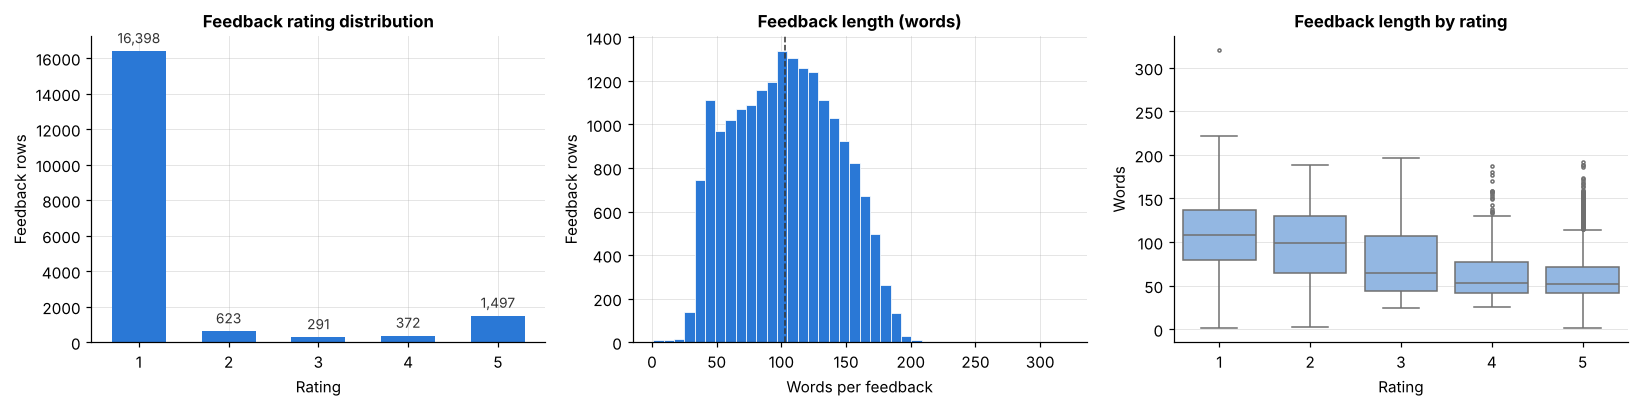

In [9]:
n_panels = 3 if RATING_COL else 2
fig, axes = plt.subplots(1, n_panels, figsize=(5 * n_panels, 3.8))
axes = np.atleast_1d(axes)
i = 0
if RATING_COL:
    counts = fb[RATING_COL].value_counts().sort_index()
    axes[i].bar(counts.index.astype(str), counts.values, color="#2a78d6", width=0.6)
    label_bars(axes[i])
    axes[i].set(title="Feedback rating distribution", xlabel="Rating", ylabel="Feedback rows")
    i += 1
wc_bins = np.arange(fb["word_count"].min() - 0.5, fb["word_count"].max() + 1.5) if fb["word_count"].max() <= 60 else 40
axes[i].hist(fb["word_count"], bins=wc_bins, color="#2a78d6", edgecolor="white", linewidth=0.5)
axes[i].axvline(fb["word_count"].median(), color="#333333", ls="--", lw=1)
axes[i].set(title="Feedback length (words)", xlabel="Words per feedback", ylabel="Feedback rows")
i += 1
if RATING_COL:
    sns.boxplot(data=fb, x=RATING_COL, y="word_count", ax=axes[i], color="#86b6ef", fliersize=2)
    axes[i].set(title="Feedback length by rating", xlabel="Rating", ylabel="Words")
else:
    exit_counts = churn[TARGET].value_counts().sort_index()
    axes[i].bar([EXIT_NAMES[k] for k in exit_counts.index], exit_counts.values,
                color=[EXIT_COLORS[k] for k in exit_counts.index], width=0.55)
    label_bars(axes[i])
    axes[i].set(title="Churn target balance", ylabel="Customers")
fig.tight_layout()
savefig(fig, "t1_feedback_eda")
plt.show()

**Task 1 notes:** _Record what stands out after running, for example: how ratings are distributed, how long typical feedback is, whether longer feedback goes with lower ratings, and what share of churn customers have feedback at all. The last point matters for Task 6, since customers with no feedback get no sentiment signal._

## Task 2: Text Cleaning and Preprocessing

Steps: lowercase, expand negative contractions, strip URLs, numbers, and punctuation, tokenize with NLTK, remove stopwords, then lemmatize with WordNet using part-of-speech tags.

Negation words (`not`, `no`, `nor`, `never`) are **kept** even though they are in the NLTK stopword list. Dropping them would turn "not happy" into "happy" and flip the sentiment the models learn from.

The lexicon scorers in Task 3 (VADER, TextBlob) run on the **raw** text instead, because they use capitalization, punctuation, and negation themselves.

In [10]:
NEGATIONS = {"no", "not", "nor", "never"}
STOP_WORDS = set(stopwords.words("english")) - NEGATIONS
lemmatizer = WordNetLemmatizer()
PUNCT_TABLE = str.maketrans({c: " " for c in string.punctuation + "\u201c\u201d\u2018\u2019\u2013\u2014\u2026"})

def normalize(text):
    text = text.lower()
    text = re.sub(r"https?://\S+|www\.\S+", " ", text)
    text = re.sub(r"\S+@\S+", " ", text)
    text = re.sub(r"\bcan['\u2019]t\b", "can not", text)
    text = re.sub(r"\bwon['\u2019]t\b", "will not", text)
    text = re.sub(r"n['\u2019]t\b", " not", text)      # don't -> do not, isn't -> is not
    text = text.translate(PUNCT_TABLE)
    text = re.sub(r"\d+", " ", text)
    return re.sub(r"\s+", " ", text).strip()

def wordnet_pos(tag):
    return {"J": wordnet.ADJ, "V": wordnet.VERB, "R": wordnet.ADV}.get(tag[0], wordnet.NOUN)

def preprocess(text):
    tokens = word_tokenize(normalize(text))
    tokens = [t for t in tokens if t not in STOP_WORDS and len(t) > 1]
    tagged = nltk.pos_tag(tokens)
    return [lemmatizer.lemmatize(tok, wordnet_pos(tag)) for tok, tag in tagged]

fb["normalized"] = fb[TEXT_COL].map(normalize)
fb["tokens"] = fb[TEXT_COL].map(preprocess)
fb["clean_text"] = fb["tokens"].str.join(" ")
fb["clean_token_count"] = fb["tokens"].str.len()

print(f"Rows that are empty after cleaning: {(fb['clean_token_count'] == 0).sum():,}")
sample = fb.sample(min(6, len(fb)), random_state=RANDOM_STATE)
display(sample[[TEXT_COL, "normalized", "clean_text"]])

Rows that are empty after cleaning: 0


,Feedback_Text,normalized,clean_text
18727,I've been nothing but an upstanding customer o...,i ve been nothing but an upstanding customer o...,nothing upstanding customer come across emerge...
7136,For anyone looking for a merchant account plea...,for anyone looking for a merchant account plea...,anyone look merchant account please stay away ...
11621,Never use this company for a VA home loan. I'm...,never use this company for a va home loan i m ...,never use company va home loan realtor year ex...
11887,"Since Comenity took over AAA Bank of America, ...",since comenity took over aaa bank of america t...,since comenity take aaa bank america issue acc...
11330,They are not what they use to be. They put my ...,they are not what they use to be they put my m...,not use put money wrong account take name chec...
11884,I am always having to change my password becau...,i am always having to change my password becau...,always change password whatever reason website...


Vocabulary after cleaning: 14,690 distinct lemmas, 963,849 tokens total


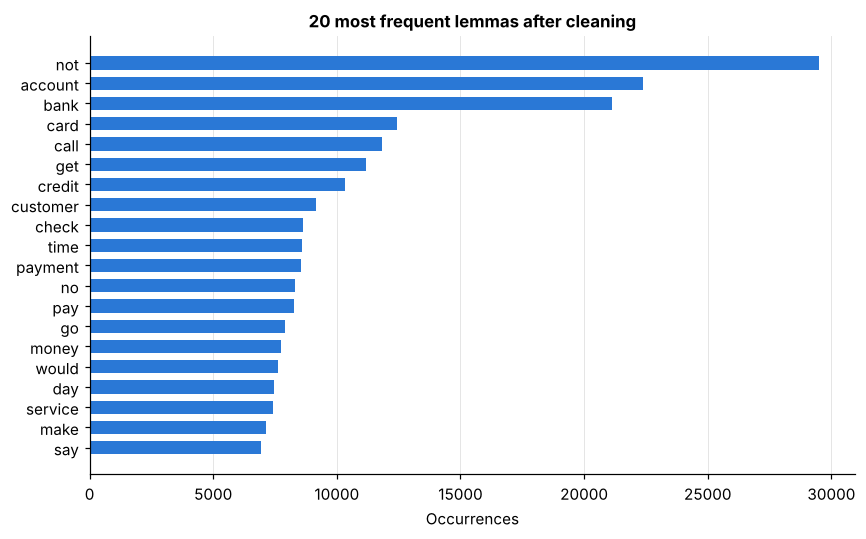

In [11]:
all_tokens = Counter(tok for toks in fb["tokens"] for tok in toks)
print(f"Vocabulary after cleaning: {len(all_tokens):,} distinct lemmas, "
      f"{sum(all_tokens.values()):,} tokens total")

top = pd.DataFrame(all_tokens.most_common(20), columns=["lemma", "count"])
fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(top["lemma"][::-1], top["count"][::-1], color="#2a78d6", height=0.65)
ax.set(title="20 most frequent lemmas after cleaning", xlabel="Occurrences")
ax.grid(axis="y", visible=False)
fig.tight_layout()
savefig(fig, "t2_top_lemmas")
plt.show()

## Task 3: Sentiment Labeling

Three ways to label each feedback as Positive, Neutral, or Negative:

* **Star rating** (when present): the bottom of the scale is Negative, the middle is Neutral, the top is Positive. On a 1 to 5 scale that is 1-2, 3, 4-5. This is the customer's own judgment, so it is the preferred label.
* **VADER** compound score, a rule-based lexicon tuned for short informal text. Standard cutoffs of +/-0.05.
* **TextBlob** polarity, a pattern-based lexicon, with the same +/-0.05 neutral band.

VADER and TextBlob scores are also kept as continuous polarity features for Task 6. Comparing the lexicon labels against the star-rating labels shows how well text-only methods recover what customers actually said.

In [12]:
sia = SentimentIntensityAnalyzer()
fb["vader_compound"] = fb[TEXT_COL].map(lambda t: sia.polarity_scores(t)["compound"])
tb_scores = fb[TEXT_COL].map(lambda t: TextBlob(t).sentiment)
fb["tb_polarity"] = tb_scores.map(lambda s: s.polarity)
fb["tb_subjectivity"] = tb_scores.map(lambda s: s.subjectivity)

def label_from_score(score, threshold):
    if score >= threshold:
        return "Positive"
    if score <= -threshold:
        return "Negative"
    return "Neutral"

fb["label_vader"] = fb["vader_compound"].map(lambda s: label_from_score(s, VADER_THRESHOLD))
fb["label_textblob"] = fb["tb_polarity"].map(lambda s: label_from_score(s, TEXTBLOB_THRESHOLD))

if RATING_COL:
    r_min, r_max = fb[RATING_COL].min(), fb[RATING_COL].max()
    def label_from_rating(r):
        if pd.isna(r):
            return np.nan
        scaled = (r - r_min) / (r_max - r_min) if r_max > r_min else 0.5
        if scaled < 0.4:
            return "Negative"
        if scaled <= 0.6:
            return "Neutral"
        return "Positive"
    fb["label_rating"] = fb[RATING_COL].map(label_from_rating)
    print(f"Rating scale {r_min:g}-{r_max:g} mapped to labels:")
    display(fb.groupby(RATING_COL)["label_rating"].first().to_frame())

display(fb[["vader_compound", "tb_polarity", "tb_subjectivity"]].describe().T.round(3))

Rating scale 1-5 mapped to labels:


,label_rating
Rating,
1,Negative
2,Negative
3,Neutral
4,Positive
5,Positive


,count,mean,std,min,25%,50%,75%,max
vader_compound,19181.0,-0.097,0.685,-0.995,-0.765,-0.255,0.612,0.996
tb_polarity,19181.0,0.008,0.208,-1.000,-0.099,0.000,0.113,1.000
tb_subjectivity,19181.0,0.457,0.168,0.000,0.352,0.456,0.559,1.000


### 3.1 Optional: refine with a pre-trained sentiment model

Set `RUN_TRANSFORMER_SENTIMENT = True` to score every feedback with `cardiffnlp/twitter-roberta-base-sentiment-latest` (a RoBERTa model fine-tuned for 3-class sentiment). It downloads about 500 MB the first time and is much slower than the lexicons, especially without a GPU.

In [13]:
if RUN_TRANSFORMER_SENTIMENT:
    from transformers import pipeline
    clf = pipeline("sentiment-analysis", model="cardiffnlp/twitter-roberta-base-sentiment-latest",
                   truncation=True, max_length=256)
    preds = clf(fb[TEXT_COL].tolist(), batch_size=64)
    fb["label_transformer"] = [p["label"].capitalize() for p in preds]
    fb["transformer_score"] = [p["score"] for p in preds]
    print(fb["label_transformer"].value_counts())
else:
    print("Skipped (RUN_TRANSFORMER_SENTIMENT = False)")

Skipped (RUN_TRANSFORMER_SENTIMENT = False)


### 3.2 Agreement between labeling methods, and the final label

In [14]:
label_cols = [c for c in ["label_rating", "label_vader", "label_textblob", "label_transformer"] if c in fb]
rows = []
for i, a in enumerate(label_cols):
    for b in label_cols[i + 1:]:
        both = fb[[a, b]].dropna()
        rows.append({"method A": a, "method B": b,
                     "agreement": (both[a] == both[b]).mean(),
                     "cohen_kappa": cohen_kappa_score(both[a], both[b])})
agreement = pd.DataFrame(rows).round(3)
display(agreement)

if LABEL_SOURCE == "auto":
    LABEL_SOURCE_USED = "rating" if RATING_COL else "vader"
else:
    LABEL_SOURCE_USED = LABEL_SOURCE
assert f"label_{LABEL_SOURCE_USED}" in fb, f"label_{LABEL_SOURCE_USED} is not available"

fb["sentiment"] = fb[f"label_{LABEL_SOURCE_USED}"]
n_missing = fb["sentiment"].isna().sum()
if n_missing:   # e.g. rating missing on some rows: fall back to VADER for those
    fb["sentiment"] = fb["sentiment"].fillna(fb["label_vader"])
    print(f"{n_missing:,} rows had no {LABEL_SOURCE_USED} label and fell back to VADER")

print(f"\nFinal sentiment label source: {LABEL_SOURCE_USED}")
dist = fb["sentiment"].value_counts().reindex(SENT_ORDER).fillna(0).astype(int)
display(pd.DataFrame({"count": dist, "share": (dist / dist.sum()).round(3)}))

,method A,method B,agreement,cohen_kappa
0,label_rating,label_vader,0.627,0.203
1,label_rating,label_textblob,0.432,0.122
2,label_vader,label_textblob,0.525,0.255



Final sentiment label source: rating


,count,share
sentiment,,
Negative,17021,0.887
Neutral,291,0.015
Positive,1869,0.097


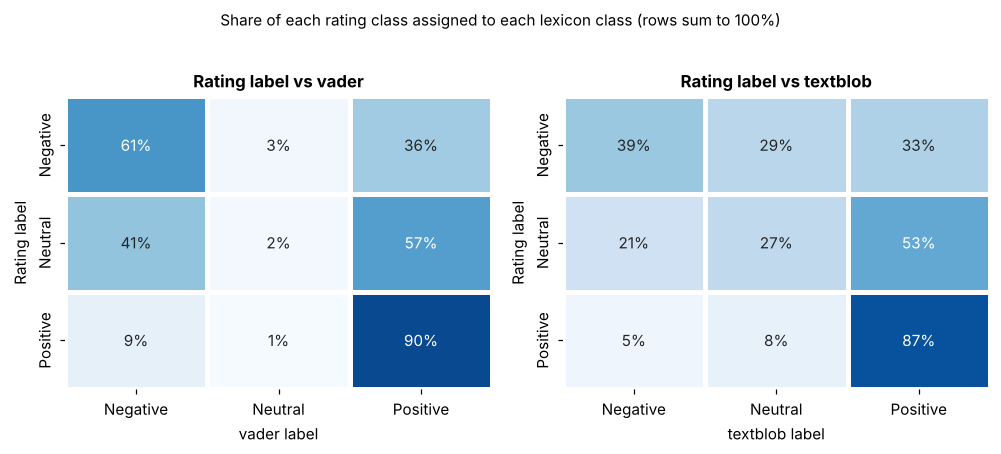

In [15]:
reference = "label_rating" if "label_rating" in fb else None
if reference:
    others = [c for c in label_cols if c != reference]
    fig, axes = plt.subplots(1, len(others), figsize=(4.6 * len(others), 4))
    axes = np.atleast_1d(axes)
    for ax, other in zip(axes, others):
        ct = pd.crosstab(fb[reference], fb[other], normalize="index").reindex(
            index=SENT_ORDER, columns=SENT_ORDER).fillna(0)
        sns.heatmap(ct, annot=True, fmt=".0%", cmap="Blues", vmin=0, vmax=1, cbar=False,
                    linewidths=2, linecolor="white", ax=ax)
        ax.set(title=f"Rating label vs {other.replace('label_', '')}",
               xlabel=other.replace("label_", "") + " label", ylabel="Rating label")
    fig.suptitle("Share of each rating class assigned to each lexicon class (rows sum to 100%)",
                 fontsize=10, y=1.02)
    fig.tight_layout()
    savefig(fig, "t3_label_agreement")
    plt.show()
else:
    print("No star ratings, so there is no customer-provided reference label to compare against.")

**Task 3 notes:** _Interpret the agreement table. Low agreement between ratings and the lexicons usually means sarcasm, domain words the lexicons do not know (for example "fee", "hold", "locked"), or ratings that do not match the written tone. If labels come from VADER (no ratings), keep in mind that the Task 5 classifiers are then learning to imitate VADER, so their scores measure that, not true customer sentiment._

## Task 4: Text Vectorization

A stratified 80/20 train/test split comes first, and every vectorizer is **fit on the training text only**, so the test set's vocabulary never leaks into training.

* **Bag-of-Words**: raw counts of unigrams and bigrams (bigrams keep phrases like "not help").
* **TF-IDF**: the same n-grams, weighted down when they appear in many documents, with sublinear term frequency.
* **Sentence embeddings** (optional): dense 384-dimension vectors from `all-MiniLM-L6-v2`.
* The BiLSTM in Task 5 learns its own word embeddings.

In [16]:
model_df = fb[fb["clean_token_count"] > 0].reset_index(drop=True)
X_text = model_df["clean_text"]
y = model_df["sentiment"]
present_classes = [c for c in SENT_ORDER if c in set(y)]

X_train, X_test, y_train, y_test, idx_train, idx_test = train_test_split(
    X_text, y, model_df.index, test_size=TEST_SIZE, stratify=y, random_state=RANDOM_STATE)
print(f"Train: {len(X_train):,} rows | Test: {len(X_test):,} rows")
display(pd.concat([y_train.value_counts(normalize=True).rename("train"),
                   y_test.value_counts(normalize=True).rename("test")], axis=1).round(3))

# Leakage check: identical texts in both splits make test scores look better than they are
overlap = X_test.isin(set(X_train)).mean()
print(f"Test texts that also appear verbatim in train: {overlap:.1%}")
if overlap > 0.2:
    print("  WARNING: many feedback texts repeat (templated data). Test scores will be optimistic; "
          "mention this in the write-up.")

Train: 15,344 rows | Test: 3,837 rows


,train,test
sentiment,,
Negative,0.887,0.887
Positive,0.097,0.097
Neutral,0.015,0.015


Test texts that also appear verbatim in train: 0.0%


In [17]:
min_df = 2 if len(X_train) >= 200 else 1
vectorizers = {
    "BoW": CountVectorizer(ngram_range=(1, 2), min_df=min_df, max_features=MAX_FEATURES),
    "TF-IDF": TfidfVectorizer(ngram_range=(1, 2), min_df=min_df, max_features=MAX_FEATURES,
                              sublinear_tf=True),
}
features = {}
for name, vec in vectorizers.items():
    Xtr = vec.fit_transform(X_train)
    Xte = vec.transform(X_test)
    features[name] = (Xtr, Xte)
    density = Xtr.nnz / (Xtr.shape[0] * Xtr.shape[1])
    print(f"{name:7s} train matrix {Xtr.shape[0]:,} x {Xtr.shape[1]:,}  (density {density:.3%})")

BoW     train matrix 15,344 x 20,000  (density 0.305%)


TF-IDF  train matrix 15,344 x 20,000  (density 0.305%)


In [18]:
# Highest average TF-IDF weight per sentiment class (training data)
tfidf_vec = vectorizers["TF-IDF"]
Xtr_tfidf = features["TF-IDF"][0]
terms = np.array(tfidf_vec.get_feature_names_out())
top_terms = {}
for cls in present_classes:
    mask = (y_train == cls).to_numpy()
    mean_w = np.asarray(Xtr_tfidf[mask].mean(axis=0)).ravel()
    top_terms[cls] = terms[mean_w.argsort()[::-1][:15]]
display(pd.DataFrame(top_terms))

,Negative,Neutral,Positive
0,not,not,merrick
1,account,bank,credit
2,bank,card,bank
3,call,credit,merrick bank
4,card,account,card
5,get,fee,great
6,customer,pay,service
7,check,like,easy
8,credit,good,always
9,no,rate,customer


In [19]:
if RUN_SENTENCE_EMBEDDINGS:
    from sentence_transformers import SentenceTransformer
    st_model = SentenceTransformer("all-MiniLM-L6-v2")
    raw_text = model_df[TEXT_COL]   # embeddings work better on natural (uncleaned) sentences
    emb_train = st_model.encode(raw_text.loc[idx_train].tolist(), batch_size=64, show_progress_bar=True)
    emb_test = st_model.encode(raw_text.loc[idx_test].tolist(), batch_size=64, show_progress_bar=True)
    features["MiniLM embeddings"] = (emb_train, emb_test)
    print("Embedding matrix:", emb_train.shape)
else:
    print("Skipped (RUN_SENTENCE_EMBEDDINGS = False)")

Skipped (RUN_SENTENCE_EMBEDDINGS = False)


## Task 5: Model Development and Evaluation

Classical models on each feature set:

* **Logistic Regression** and **Linear SVM**, both with `class_weight="balanced"` so the minority sentiment class is not ignored.
* **Multinomial Naive Bayes** as a fast baseline (count-style features only).

Metrics are accuracy plus **macro** precision, recall, and F1. Macro averaging weights each class equally, which is the honest choice when one sentiment dominates. Weighted F1 is reported too.

In [20]:
def score_row(model, feats, y_true, y_pred):
    return {
        "model": model, "features": feats,
        "accuracy": accuracy_score(y_true, y_pred),
        "precision_macro": precision_score(y_true, y_pred, average="macro", zero_division=0),
        "recall_macro": recall_score(y_true, y_pred, average="macro", zero_division=0),
        "f1_macro": f1_score(y_true, y_pred, average="macro", zero_division=0),
        "f1_weighted": f1_score(y_true, y_pred, average="weighted", zero_division=0),
    }

classical_models = {
    "Logistic Regression": LogisticRegression(max_iter=3000, class_weight="balanced", C=2.0),
    "Linear SVM": LinearSVC(class_weight="balanced", C=0.5),
    "Naive Bayes": MultinomialNB(alpha=0.5),
}

results, fitted, test_preds = [], {}, {}
for feat_name, (Xtr, Xte) in features.items():
    for model_name, proto in classical_models.items():
        if model_name == "Naive Bayes" and feat_name not in ("BoW", "TF-IDF"):
            continue   # NB needs non-negative count-like features
        model = clone(proto).fit(Xtr, y_train)
        pred = model.predict(Xte)
        results.append(score_row(model_name, feat_name, y_test, pred))
        fitted[(model_name, feat_name)] = model
        test_preds[(model_name, feat_name)] = pred

classical_results = pd.DataFrame(results).sort_values("f1_macro", ascending=False).reset_index(drop=True)
display(classical_results.round(4))

,model,features,accuracy,precision_macro,recall_macro,f1_macro,f1_weighted
0,Logistic Regression,TF-IDF,0.9502,0.6784,0.6617,0.6676,0.9486
1,Logistic Regression,BoW,0.9474,0.6502,0.6517,0.6501,0.9465
2,Linear SVM,TF-IDF,0.9573,0.7033,0.6017,0.6239,0.9503
3,Linear SVM,BoW,0.9510,0.6295,0.6089,0.6144,0.9464
4,Naive Bayes,BoW,0.9429,0.7004,0.6059,0.6012,0.9377
5,Naive Bayes,TF-IDF,0.9302,0.6347,0.4795,0.5226,0.9133


Best classical model: Logistic Regression on TF-IDF

              precision    recall  f1-score   support

    Negative      0.974     0.976     0.975      3405
     Neutral      0.250     0.172     0.204        58
    Positive      0.811     0.837     0.824       374

    accuracy                          0.950      3837
   macro avg      0.678     0.662     0.668      3837
weighted avg      0.947     0.950     0.949      3837



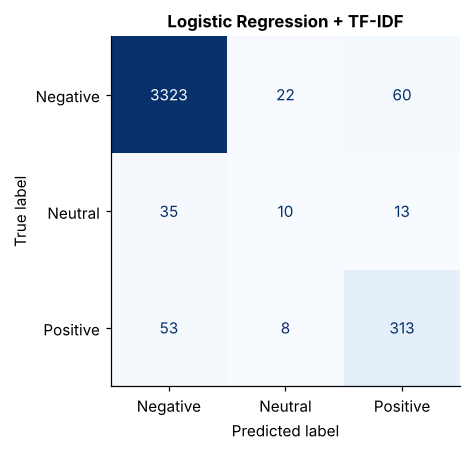

In [21]:
best_model_name, best_feat_name = classical_results.loc[0, ["model", "features"]]
best_pred = test_preds[(best_model_name, best_feat_name)]
print(f"Best classical model: {best_model_name} on {best_feat_name}\n")
print(classification_report(y_test, best_pred, labels=present_classes, digits=3, zero_division=0))

fig, ax = plt.subplots(figsize=(4.8, 4.2))
ConfusionMatrixDisplay.from_predictions(y_test, best_pred, labels=present_classes, cmap="Blues",
                                        colorbar=False, ax=ax)
ax.set(title=f"{best_model_name} + {best_feat_name}")
ax.grid(False)
fig.tight_layout()
savefig(fig, "t5_confusion_best_classical")
plt.show()

In [22]:
# Robustness check: 5-fold cross-validated macro F1 for the best classical pipeline on all labeled text
if best_feat_name in vectorizers:
    best_pipe = Pipeline([("vec", clone(vectorizers[best_feat_name])),
                          ("clf", clone(classical_models[best_model_name]))])
    cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
    cv_f1 = cross_val_score(best_pipe, X_text, y, cv=cv, scoring="f1_macro", n_jobs=-1)
    print(f"5-fold macro F1: {cv_f1.mean():.4f} +/- {cv_f1.std():.4f}  (folds: {np.round(cv_f1, 4)})")

5-fold macro F1: 0.6478 +/- 0.0170  (folds: [0.6635 0.6576 0.64   0.6599 0.6179])


### 5.1 Deep learning: Bidirectional LSTM

Architecture: `TextVectorization -> Embedding(64) -> Bidirectional LSTM(64) -> Dropout -> Dense(32) -> Softmax`. The embedding layer is trained from scratch on this corpus, with class weights and early stopping on validation loss.

Container notes (from the deeplearning NVIDIA container fixes): the cell forces `TF_USE_LEGACY_KERAS=0` before importing TensorFlow and compiles with `jit_compile=False`, which is what TF 2.21 needs on the RTX 5060 Ti. Both settings are harmless on CPU-only machines.

In [23]:
lstm_available = False
if RUN_LSTM:
    os.environ["TF_USE_LEGACY_KERAS"] = "0"
    os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")
    try:
        import tensorflow as tf
        from tensorflow import keras
        lstm_available = True
        print("TensorFlow", tf.__version__, "| GPUs:", tf.config.list_physical_devices("GPU"))
    except ImportError:
        print("TensorFlow is not installed in this environment, so the LSTM is skipped. "
              "Run this notebook in the deeplearning container to include it.")
else:
    print("Skipped (RUN_LSTM = False)")

TensorFlow 2.21.0 | GPUs: []


In [24]:
if lstm_available:
    keras.utils.set_random_seed(RANDOM_STATE)
    class_to_int = {c: i for i, c in enumerate(present_classes)}
    ytr_int = y_train.map(class_to_int).to_numpy()
    yte_int = y_test.map(class_to_int).to_numpy()

    seq_len = int(np.clip(np.percentile(model_df["clean_token_count"], 95), 10, 200))
    text_vec = keras.layers.TextVectorization(max_tokens=MAX_FEATURES, output_mode="int",
                                              output_sequence_length=seq_len)
    text_vec.adapt(X_train.to_numpy())
    Xtr_seq = text_vec(X_train.to_numpy()).numpy()
    Xte_seq = text_vec(X_test.to_numpy()).numpy()
    vocab_size = len(text_vec.get_vocabulary())
    print(f"Sequence length {seq_len}, vocabulary {vocab_size:,}")

    lstm = keras.Sequential([
        keras.Input(shape=(seq_len,)),
        keras.layers.Embedding(vocab_size, 64, mask_zero=True),
        keras.layers.Bidirectional(keras.layers.LSTM(64)),
        keras.layers.Dropout(0.3),
        keras.layers.Dense(32, activation="relu"),
        keras.layers.Dense(len(present_classes), activation="softmax"),
    ])
    lstm.compile(optimizer=keras.optimizers.Adam(1e-3), loss="sparse_categorical_crossentropy",
                 metrics=["accuracy"], jit_compile=False)
    lstm.summary()

    weights = compute_class_weight("balanced", classes=np.arange(len(present_classes)), y=ytr_int)
    history = lstm.fit(
        Xtr_seq, ytr_int, validation_split=0.15, epochs=LSTM_EPOCHS, batch_size=64,
        class_weight=dict(enumerate(weights)), verbose=2,
        callbacks=[keras.callbacks.EarlyStopping(monitor="val_loss", patience=3,
                                                 restore_best_weights=True)])

Sequence length 81, vocabulary 13,414


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 81, 64)         │       858,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional (Bidirectional)   │ (None, 128)            │        66,048 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │         4,128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 3)              │            99 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 928,771 (3.54 MB)

 Trainable params: 928,771 (3.54 MB)

...

204/204 - 21s - 102ms/step - accuracy: 0.9918 - loss: 0.0164 - val_accuracy: 0.9414 - val_loss: 0.2850


Epoch 10/15


204/204 - 16s - 76ms/step - accuracy: 0.9945 - loss: 0.0103 - val_accuracy: 0.9409 - val_loss: 0.3145


Epoch 11/15


204/204 - 21s - 101ms/step - accuracy: 0.9957 - loss: 0.0078 - val_accuracy: 0.9366 - val_loss: 0.3403


              precision    recall  f1-score   support

    Negative      0.968     0.954     0.961      3405
     Neutral      0.110     0.155     0.129        58
    Positive      0.725     0.770     0.747       374

    accuracy                          0.924      3837
   macro avg      0.601     0.627     0.612      3837
weighted avg      0.931     0.924     0.928      3837



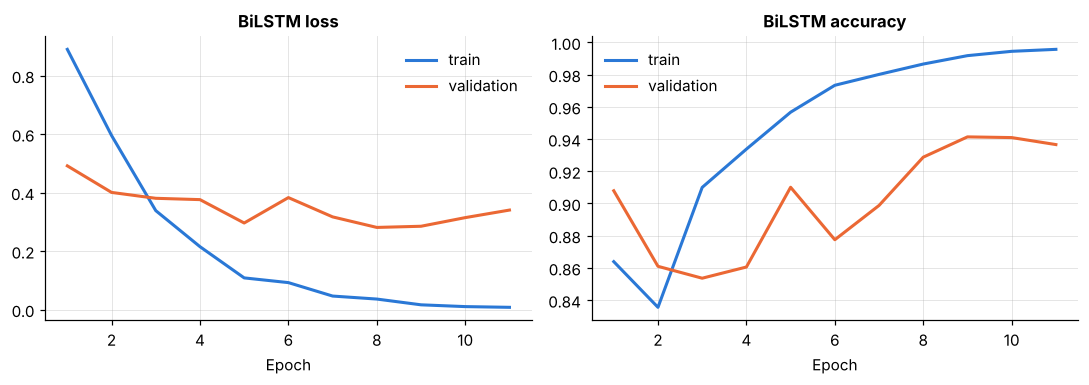

In [25]:
if lstm_available:
    lstm_pred = np.array(present_classes)[lstm.predict(Xte_seq, verbose=0).argmax(axis=1)]
    lstm_row = score_row("BiLSTM", "Learned embeddings", y_test, lstm_pred)
    print(classification_report(y_test, lstm_pred, labels=present_classes, digits=3, zero_division=0))

    hist = pd.DataFrame(history.history)
    fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
    for ax, metric in zip(axes, ["loss", "accuracy"]):
        ax.plot(hist.index + 1, hist[metric], color="#2a78d6", lw=2, label="train")
        ax.plot(hist.index + 1, hist[f"val_{metric}"], color="#eb6834", lw=2, label="validation")
        ax.set(title=f"BiLSTM {metric}", xlabel="Epoch")
        ax.legend(frameon=False)
    fig.tight_layout()
    savefig(fig, "t5_lstm_training")
    plt.show()

### 5.2 Classical vs deep learning comparison

,model,features,accuracy,precision_macro,recall_macro,f1_macro,f1_weighted,approach
0,Logistic Regression,TF-IDF,0.9502,0.6784,0.6617,0.6676,0.9486,Classical
1,Logistic Regression,BoW,0.9474,0.6502,0.6517,0.6501,0.9465,Classical
2,Linear SVM,TF-IDF,0.9573,0.7033,0.6017,0.6239,0.9503,Classical
3,Linear SVM,BoW,0.9510,0.6295,0.6089,0.6144,0.9464,Classical
4,BiLSTM,Learned embeddings,0.9244,0.6010,0.6266,0.6123,0.9277,Deep learning
5,Naive Bayes,BoW,0.9429,0.7004,0.6059,0.6012,0.9377,Classical
6,Naive Bayes,TF-IDF,0.9302,0.6347,0.4795,0.5226,0.9133,Classical


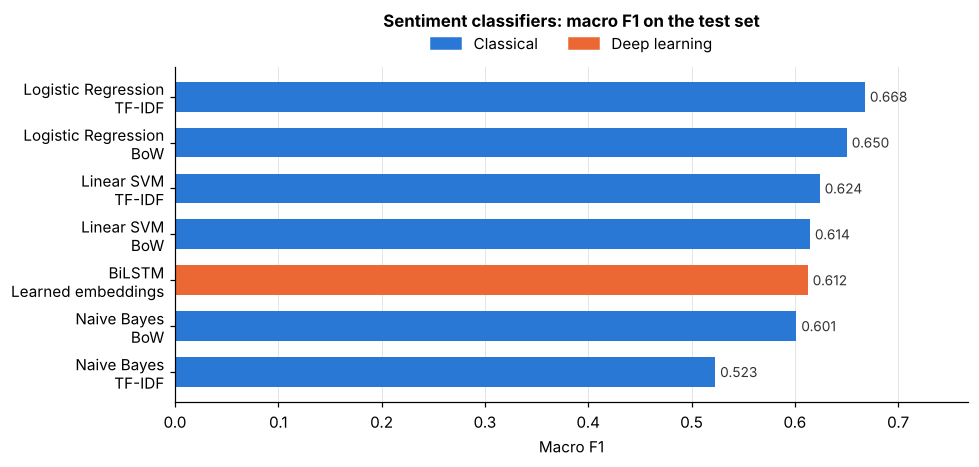

In [26]:
all_results = classical_results.copy()
if lstm_available:
    all_results = pd.concat([all_results, pd.DataFrame([lstm_row])], ignore_index=True)
all_results["approach"] = np.where(all_results["model"] == "BiLSTM", "Deep learning", "Classical")
all_results = all_results.sort_values("f1_macro", ascending=False).reset_index(drop=True)
display(all_results.round(4))
all_results.to_csv(OUT_DIR / "sentiment_model_comparison.csv", index=False)

plot_df = all_results.assign(label=all_results["model"] + "\n" + all_results["features"])
fig, ax = plt.subplots(figsize=(9, 0.45 * len(plot_df) + 1.2))
colors = ["#eb6834" if a == "Deep learning" else "#2a78d6" for a in plot_df["approach"]]
ax.barh(plot_df["label"][::-1], plot_df["f1_macro"][::-1], color=colors[::-1], height=0.65)
for yy, v in enumerate(plot_df["f1_macro"][::-1]):
    ax.text(v + 0.005, yy, f"{v:.3f}", va="center", fontsize=9, color="#333333")
ax.set(title="Sentiment classifiers: macro F1 on the test set", xlabel="Macro F1",
       xlim=(0, min(1.0, plot_df["f1_macro"].max() + 0.1)))
ax.grid(axis="y", visible=False)
ax.legend(handles=[Patch(color="#2a78d6", label="Classical"), Patch(color="#eb6834", label="Deep learning")],
          frameon=False, loc="lower center", bbox_to_anchor=(0.5, 1.0), ncol=2)
ax.set_title(ax.get_title(), pad=26)
fig.tight_layout()
savefig(fig, "t5_model_comparison")
plt.show()

**Task 5 notes:** _Compare the approaches. On short, fairly formulaic feedback, linear models on TF-IDF are often as good as or better than an LSTM trained from scratch, at a fraction of the cost. An LSTM pays off with more data, longer text, or pre-trained embeddings. Note which classes get confused most (usually Neutral)._

## Task 6: Integration with the Churn Dataset

1. Generate a **predicted sentiment for every feedback row** with the best classical pipeline. Out-of-fold predictions (5-fold `cross_val_predict`) are used, so no row is predicted by a model that saw it during training.
2. Aggregate to one row per customer (a customer can leave several pieces of feedback).
3. Left-join onto the churn data by customer ID, so every churn customer is kept. Customers without feedback get neutral defaults plus a `has_feedback = 0` flag.

In [27]:
oof_pipe = Pipeline([("vec", clone(vectorizers.get(best_feat_name, vectorizers["TF-IDF"]))),
                     ("clf", clone(classical_models[best_model_name]))])
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
model_df["predicted_sentiment"] = cross_val_predict(oof_pipe, X_text, y, cv=cv, n_jobs=-1)
print(f"Out-of-fold macro F1 of predicted_sentiment: "
      f"{f1_score(y, model_df['predicted_sentiment'], average='macro'):.4f}")

fb = fb.merge(model_df[[ID_COL, TEXT_COL, "predicted_sentiment"]].drop_duplicates([ID_COL, TEXT_COL]),
              on=[ID_COL, TEXT_COL], how="left")
fb["predicted_sentiment"] = fb["predicted_sentiment"].fillna("Neutral")   # rows that were empty after cleaning
fb.drop(columns=["tokens"]).to_csv(OUT_DIR / "feedback_with_sentiment.csv", index=False)

Out-of-fold macro F1 of predicted_sentiment: 0.6480


In [28]:
def dominant(series):
    counts = series.value_counts().reindex(SENT_ORDER, fill_value=0)
    return counts.idxmax()            # ties resolve toward Negative, the conservative read

agg_spec = {
    "feedback_count": (TEXT_COL, "size"),
    "vader_mean": ("vader_compound", "mean"),
    "vader_min": ("vader_compound", "min"),
    "tb_polarity_mean": ("tb_polarity", "mean"),
    "tb_subjectivity_mean": ("tb_subjectivity", "mean"),
    "neg_share": ("predicted_sentiment", lambda s: (s == "Negative").mean()),
    "pos_share": ("predicted_sentiment", lambda s: (s == "Positive").mean()),
    "avg_word_count": ("word_count", "mean"),
    "dominant_predicted": ("predicted_sentiment", dominant),
    "dominant_label": ("sentiment", dominant),
}
if RATING_COL:
    agg_spec["avg_rating"] = (RATING_COL, "mean")
cust_sent = fb.groupby(ID_COL).agg(**agg_spec).reset_index()
print(f"Customer-level sentiment table: {cust_sent.shape}")
display(cust_sent.head())

Customer-level sentiment table: (19181, 12)


,CustomerId,feedback_count,vader_mean,vader_min,tb_polarity_mean,tb_subjectivity_mean,neg_share,pos_share,avg_word_count,dominant_predicted,dominant_label,avg_rating
0,110000,1,0.4478,0.4478,0.180000,0.291429,0.0,0.0,69.0,Neutral,Negative,1.0
1,110001,1,-0.6597,-0.6597,-0.500000,0.300000,1.0,0.0,52.0,Negative,Negative,1.0
2,110002,1,-0.8600,-0.8600,0.002865,0.321212,1.0,0.0,138.0,Negative,Negative,1.0
3,110003,1,-0.7401,-0.7401,-0.060000,0.713333,1.0,0.0,57.0,Negative,Negative,1.0
4,110004,1,0.4478,0.4478,0.047143,0.438571,1.0,0.0,44.0,Negative,Negative,1.0


In [29]:
STRUCTURED_COLS = [c for c in churn.columns if c not in (ID_COL, TARGET)]

unified = churn.merge(cust_sent, on=ID_COL, how="left", validate="m:1")
unified["has_feedback"] = unified["feedback_count"].notna().astype(int)

fill_neutral = {"feedback_count": 0, "vader_mean": 0.0, "vader_min": 0.0, "tb_polarity_mean": 0.0,
                "tb_subjectivity_mean": 0.0, "neg_share": 0.0, "pos_share": 0.0, "avg_word_count": 0.0,
                "dominant_predicted": "No Feedback", "dominant_label": "No Feedback"}
unified = unified.fillna(fill_neutral)   # avg_rating stays NaN: there is no neutral rating to invent

SENTIMENT_FEATURES = ["has_feedback", "feedback_count", "vader_mean", "vader_min", "tb_polarity_mean",
                      "tb_subjectivity_mean", "neg_share", "pos_share", "dominant_predicted"]
if RATING_COL:
    SENTIMENT_FEATURES.append("avg_rating")

orphans = len(set(cust_sent[ID_COL]) - set(churn[ID_COL]))
print(f"Unified dataset: {unified.shape[0]:,} customers x {unified.shape[1]} columns")
print(f"Customers with feedback: {unified['has_feedback'].sum():,} ({unified['has_feedback'].mean():.1%})")
print(f"Feedback customers not in the churn file (dropped by the left join): {orphans:,}")
unified.to_csv(OUT_DIR / "unified_churn_sentiment.csv", index=False)
display(unified.head())

Unified dataset: 10,000 customers x 25 columns
Customers with feedback: 9,957 (99.6%)
Feedback customers not in the churn file (dropped by the left join): 9,224


,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,feedback_count,vader_mean,vader_min,tb_polarity_mean,tb_subjectivity_mean,neg_share,pos_share,avg_word_count,dominant_predicted,dominant_label,avg_rating,has_feedback
0,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1,1.0,0.8976,0.8976,0.101417,0.775000,0.0,1.0,52.0,Positive,Positive,5.0,1
1,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0,1.0,0.9774,0.9774,0.540000,0.757778,0.0,1.0,61.0,Positive,Positive,5.0,1
2,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1,1.0,0.9552,0.9552,-0.038294,0.469643,0.0,1.0,115.0,Positive,Positive,4.0,1
3,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0,1.0,0.9849,0.9849,0.691667,0.758333,0.0,1.0,108.0,Positive,Positive,5.0,1
4,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0,1.0,0.9331,0.9331,0.153363,0.510614,1.0,0.0,145.0,Negative,Positive,5.0,1


### 6.1 Does sentiment improve churn prediction?

Same models, same folds, two feature sets:

* **Structured only**: the original churn attributes (row number, ID, and surname removed).
* **Structured + sentiment**: the same plus the customer-level sentiment features.

Scored with 5-fold stratified cross-validation. ROC-AUC is the headline because it does not depend on a decision threshold. The comparison is repeated on the feedback-only subset, since customers without feedback cannot benefit from sentiment.

**Caveat for the write-up:** this only measures real predictive value if the feedback was given **before** the churn decision. Feedback written at exit (for example a closing survey) would leak the outcome and inflate the gain.

In [30]:
DROP_COLS = {"RowNumber", "Surname", ID_COL, TARGET}
base_cols = [c for c in STRUCTURED_COLS if c not in DROP_COLS]

def make_pipe(cols, model):
    num = [c for c in cols if pd.api.types.is_numeric_dtype(unified[c])]
    cat = [c for c in cols if c not in num]
    pre = ColumnTransformer([
        ("num", Pipeline([("impute", SimpleImputer(strategy="median")), ("scale", StandardScaler())]), num),
        ("cat", OneHotEncoder(handle_unknown="ignore"), cat),
    ])
    return Pipeline([("pre", pre), ("model", model)])

churn_models = {
    "Logistic Regression": LogisticRegression(max_iter=3000, class_weight="balanced"),
    "Gradient Boosting": HistGradientBoostingClassifier(random_state=RANDOM_STATE, class_weight="balanced",
                                                        max_iter=300, learning_rate=0.05),
}
feature_sets = {"Structured only": base_cols, "Structured + sentiment": base_cols + SENTIMENT_FEATURES}
subsets = {"All customers": unified, "Customers with feedback": unified[unified["has_feedback"] == 1]}
scoring = ["roc_auc", "f1", "precision", "recall", "accuracy"]

rows = []
for subset_name, data in subsets.items():
    if subset_name != "All customers" and len(data) == len(unified):
        print(f"Skipping '{subset_name}': every churn customer has feedback, so it equals 'All customers'")
        continue
    if len(data) < 200 or data[TARGET].nunique() < 2:
        print(f"Skipping '{subset_name}' (too few rows or one class only)")
        continue
    cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
    for fs_name, cols in feature_sets.items():
        for m_name, m in churn_models.items():
            res = cross_validate(make_pipe(cols, m), data[cols], data[TARGET], cv=cv, scoring=scoring, n_jobs=-1)
            row = {"subset": subset_name, "features": fs_name, "model": m_name}
            row.update({k: res[f"test_{k}"].mean() for k in scoring})
            row["roc_auc_std"] = res["test_roc_auc"].std()
            rows.append(row)

churn_results = pd.DataFrame(rows)
display(churn_results.round(4))
churn_results.to_csv(OUT_DIR / "churn_model_comparison.csv", index=False)

base = churn_results[churn_results["features"] == "Structured only"].set_index(["subset", "model"])
enh = churn_results[churn_results["features"] == "Structured + sentiment"].set_index(["subset", "model"])
lift = pd.DataFrame({
    "roc_auc_structured": base["roc_auc"], "roc_auc_with_sentiment": enh["roc_auc"],
    "roc_auc_gain": enh["roc_auc"] - base["roc_auc"],
    "f1_structured": base["f1"], "f1_with_sentiment": enh["f1"], "f1_gain": enh["f1"] - base["f1"],
})
display(lift.round(4))

,subset,features,model,roc_auc,f1,precision,recall,accuracy,roc_auc_std
0,All customers,Structured only,Logistic Regression,0.7693,0.4934,0.3838,0.6912,0.7111,0.0145
1,All customers,Structured only,Gradient Boosting,0.8578,0.6082,0.5523,0.6775,0.8222,0.0074
2,All customers,Structured + sentiment,Logistic Regression,0.7683,0.4923,0.3833,0.6888,0.7109,0.0139
3,All customers,Structured + sentiment,Gradient Boosting,0.8591,0.6107,0.5698,0.6588,0.8290,0.0035
4,Customers with feedback,Structured only,Logistic Regression,0.7688,0.4929,0.3832,0.6906,0.7103,0.0099
5,Customers with feedback,Structured only,Gradient Boosting,0.8537,0.6081,0.5523,0.6768,0.8220,0.0053
6,Customers with feedback,Structured + sentiment,Logistic Regression,0.7686,0.4932,0.3841,0.6892,0.7114,0.0102
7,Customers with feedback,Structured + sentiment,Gradient Boosting,0.8567,0.6146,0.5729,0.6631,0.8305,0.0042


roc_auc_structured  roc_auc_with_sentiment  roc_auc_gain  f1_structured  f1_with_sentiment  \
subset                  model                                                                                                             
All customers           Logistic Regression              0.7693                  0.7683       -0.0010         0.4934             0.4923   
                        Gradient Boosting                0.8578                  0.8591        0.0013         0.6082             0.6107   
Customers with feedback Logistic Regression              0.7688                  0.7686       -0.0002         0.4929             0.4932   
                        Gradient Boosting                0.8537                  0.8567        0.0030         0.6081             0.6146   

                                             f1_gain  
subset                  model                         
All customers           Logistic Regression  -0.0011  
                        Gradient Boosting     0.0025  
Customers with feedback Logistic Regression   0.0004  
                        Gradient Boosting     0.0065

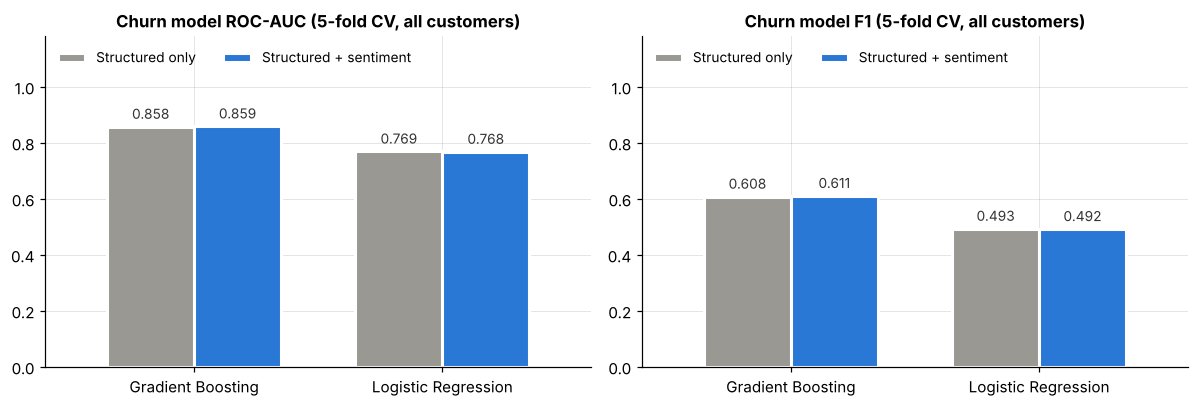

In [31]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=False)
plot_sub = churn_results[churn_results["subset"] == "All customers"]
for ax, metric in zip(axes, ["roc_auc", "f1"]):
    piv = plot_sub.pivot(index="model", columns="features", values=metric)[
        ["Structured only", "Structured + sentiment"]]
    piv.plot.bar(ax=ax, color=["#9a9893", "#2a78d6"], width=0.7, rot=0, edgecolor="white", linewidth=2)
    label_bars(ax, fmt="{:.3f}")
    ax.set(title=f"Churn model {metric.upper().replace('_', '-')} (5-fold CV, all customers)",
           xlabel="", ylim=(0, 1.18))
    ax.legend(frameon=False, loc="upper left", ncol=2, fontsize=9)
fig.tight_layout()
savefig(fig, "t6_churn_with_without_sentiment")
plt.show()

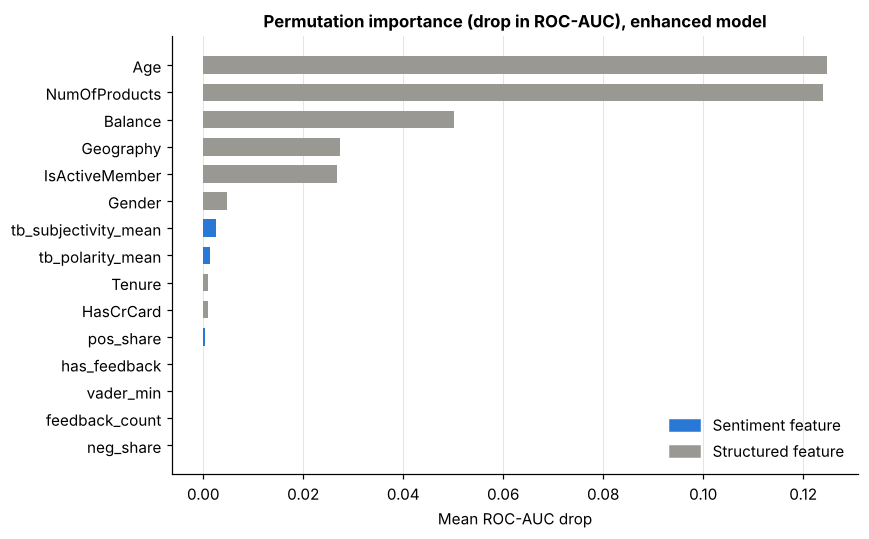

In [32]:
# Which features drive the enhanced gradient boosting model? (permutation importance on a held-out split)
cols = feature_sets["Structured + sentiment"]
Xtr_c, Xte_c, ytr_c, yte_c = train_test_split(unified[cols], unified[TARGET], test_size=0.25,
                                              stratify=unified[TARGET], random_state=RANDOM_STATE)
gb_pipe = make_pipe(cols, clone(churn_models["Gradient Boosting"])).fit(Xtr_c, ytr_c)
perm = permutation_importance(gb_pipe, Xte_c, yte_c, scoring="roc_auc", n_repeats=10,
                              random_state=RANDOM_STATE, n_jobs=-1)
imp = pd.Series(perm.importances_mean, index=cols).sort_values(ascending=False).head(15)

fig, ax = plt.subplots(figsize=(8, 5))
colors = ["#2a78d6" if c in SENTIMENT_FEATURES else "#9a9893" for c in imp.index]
ax.barh(imp.index[::-1], imp.values[::-1], color=colors[::-1], height=0.65)
ax.set(title="Permutation importance (drop in ROC-AUC), enhanced model", xlabel="Mean ROC-AUC drop")
ax.grid(axis="y", visible=False)
ax.legend(handles=[Patch(color="#2a78d6", label="Sentiment feature"),
                   Patch(color="#9a9893", label="Structured feature")], frameon=False, loc="lower right")
fig.tight_layout()
savefig(fig, "t6_feature_importance")
plt.show()

## Task 7: Visualization and Insights

### 7.1 Sentiment distribution

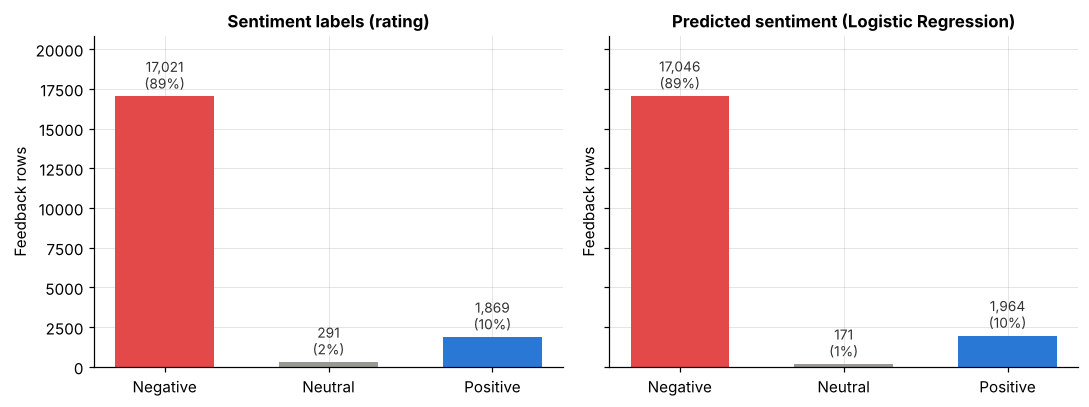

In [33]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8), sharey=True)
for ax, col, title in [(axes[0], "sentiment", f"Sentiment labels ({LABEL_SOURCE_USED})"),
                       (axes[1], "predicted_sentiment", f"Predicted sentiment ({best_model_name})")]:
    counts = fb[col].value_counts().reindex(SENT_ORDER).fillna(0)
    bars = ax.bar(counts.index, counts.values, color=[SENT_COLORS[c] for c in counts.index], width=0.6)
    ax.bar_label(bars, labels=[f"{v:,.0f}\n({v / counts.sum():.0%})" for v in counts.values],
                 padding=3, fontsize=9, color="#333333")
    ax.set(title=title, ylabel="Feedback rows")
    ax.set_ylim(0, counts.max() * 1.22)
fig.tight_layout()
savefig(fig, "t7_sentiment_distribution")
plt.show()

### 7.2 Sentiment polarity

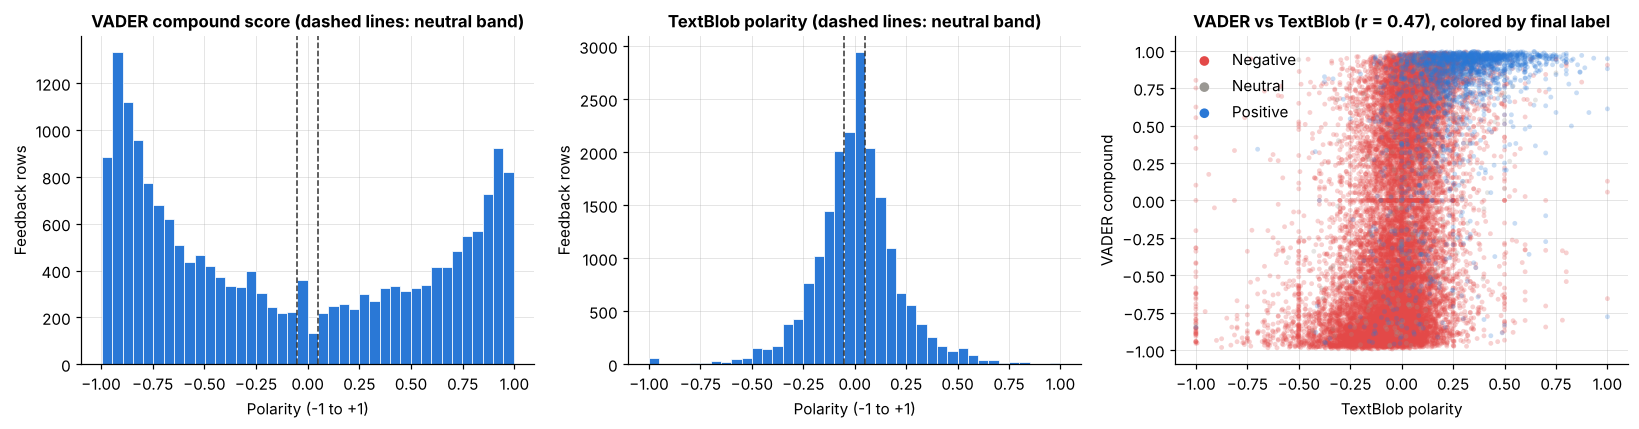

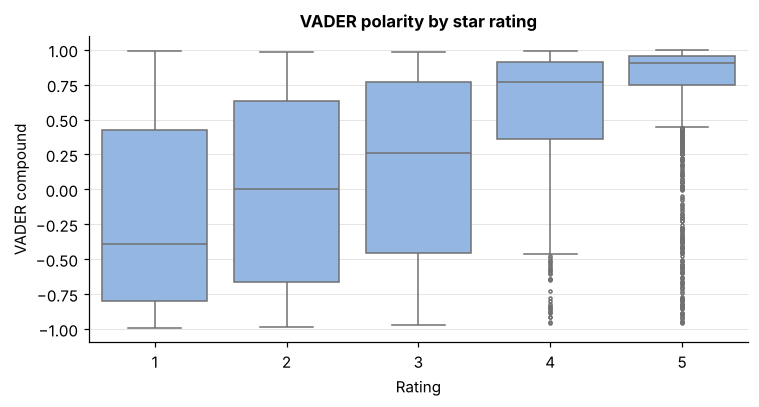

In [34]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col, thr, title in [(axes[0], "vader_compound", VADER_THRESHOLD, "VADER compound score"),
                            (axes[1], "tb_polarity", TEXTBLOB_THRESHOLD, "TextBlob polarity")]:
    ax.hist(fb[col], bins=40, color="#2a78d6", edgecolor="white", linewidth=0.5)
    for t in (-thr, thr):
        ax.axvline(t, color="#333333", ls="--", lw=1)
    ax.set(title=f"{title} (dashed lines: neutral band)", xlabel="Polarity (-1 to +1)", ylabel="Feedback rows")

for cls in SENT_ORDER:
    sub = fb[fb["sentiment"] == cls]
    axes[2].scatter(sub["tb_polarity"], sub["vader_compound"], s=10 if len(fb) > 3000 else 14,
                    alpha=0.25 if len(fb) > 3000 else 0.5, color=SENT_COLORS[cls], label=cls,
                    edgecolors="none")
r = fb[["tb_polarity", "vader_compound"]].corr().iloc[0, 1]
axes[2].set(title=f"VADER vs TextBlob (r = {r:.2f}), colored by final label",
            xlabel="TextBlob polarity", ylabel="VADER compound")
leg = axes[2].legend(frameon=False, markerscale=2)
for h in leg.legend_handles:
    h.set_alpha(1)
fig.tight_layout()
savefig(fig, "t7_polarity")
plt.show()

if RATING_COL:
    fig, ax = plt.subplots(figsize=(7, 3.8))
    sns.boxplot(data=fb, x=RATING_COL, y="vader_compound", color="#86b6ef", fliersize=2, ax=ax)
    ax.set(title="VADER polarity by star rating", xlabel="Rating", ylabel="VADER compound")
    fig.tight_layout()
    savefig(fig, "t7_polarity_by_rating")
    plt.show()

### 7.3 Word clouds by sentiment

Word cloud excludes 94 generic/bank-name words


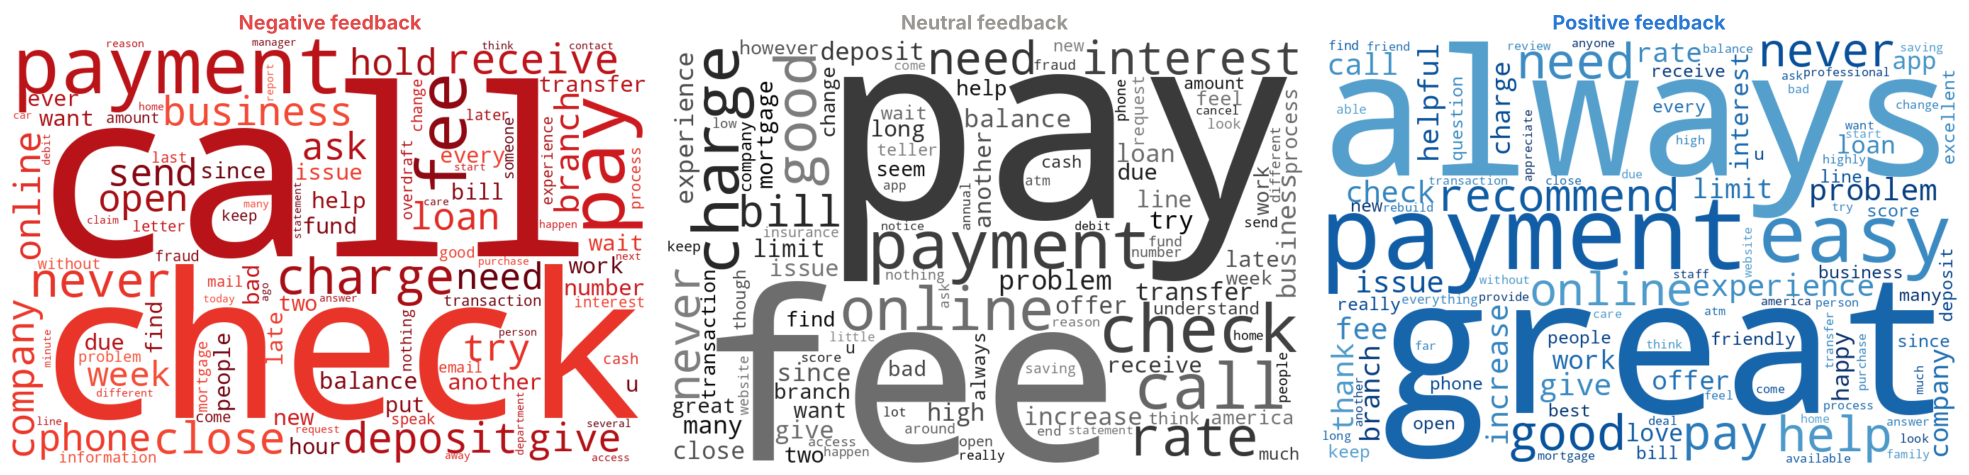

In [35]:
wc_stop = set(WORDCLOUD_EXTRA_STOPWORDS)
bank_col = find_col(fb, ["Bank_Name", "BankName", "Bank"], exclude=[ID_COL, TEXT_COL])
if bank_col:
    for name in fb[bank_col].dropna().unique():
        wc_stop |= {t for t in re.split(r"[\s_\-]+", str(name).lower()) if len(t) > 2}
    wc_stop |= {"bofa", "boa", "citi", "wells", "fargo", "chase"}
print(f"Word cloud excludes {len(wc_stop)} generic/bank-name words")

classes_with_text = [c for c in SENT_ORDER if fb.loc[fb["sentiment"] == c, "clean_text"].str.len().sum() > 0]
fig, axes = plt.subplots(1, len(classes_with_text), figsize=(6 * len(classes_with_text), 4.2))
axes = np.atleast_1d(axes)
for ax, cls in zip(axes, classes_with_text):
    text = " ".join(fb.loc[fb["sentiment"] == cls, "clean_text"])
    cmap = plt.get_cmap(SENT_CMAPS[cls])
    def color_func(word, font_size, position, orientation, random_state=None, _cmap=cmap, **kw):
        r, g, b, _ = _cmap(0.55 + 0.45 * random_state.random())   # skip the pale end of the ramp
        return f"rgb({int(r * 255)}, {int(g * 255)}, {int(b * 255)})"
    wc = WordCloud(width=900, height=600, background_color="white", color_func=color_func,
                   max_words=100, collocations=False, stopwords=wc_stop,
                   random_state=RANDOM_STATE).generate(text)
    ax.imshow(wc, interpolation="bilinear")
    ax.set_title(f"{cls} feedback", color=SENT_COLORS[cls], fontsize=13)
    ax.axis("off")
fig.tight_layout()
savefig(fig, "t7_wordclouds")
plt.show()

### 7.4 Sentiment polarity vs churn (`Exited`)

Correlations use **customers with feedback only**. Including customers without feedback would mix in thousands of artificial zeros from the neutral fill. `Exited` is binary, so the Pearson correlation here is the point-biserial correlation, reported with its p-value.

,feature,r_with_Exited,p_value,n
5,pos_share,0.0114,0.2551,9957
2,tb_polarity_mean,0.0110,0.2735,9957
0,vader_mean,0.0108,0.2833,9957
1,vader_min,0.0108,0.2833,9957
4,neg_share,-0.0089,0.3751,9957
3,tb_subjectivity_mean,0.0087,0.3842,9957
6,avg_rating,0.0036,0.7197,9957


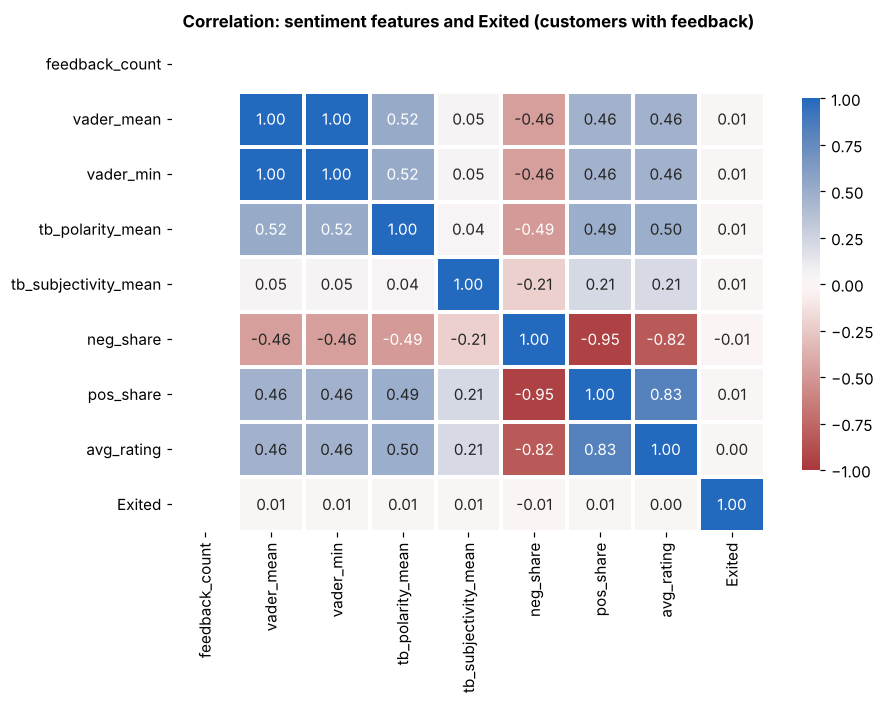

In [36]:
fb_customers = unified[unified["has_feedback"] == 1].copy()
num_sent = [c for c in SENTIMENT_FEATURES if c not in ("has_feedback", "dominant_predicted")]

corr_rows = []
for c in num_sent:
    valid = fb_customers[[c, TARGET]].dropna()
    if valid[c].nunique() > 1:
        r, p = stats.pointbiserialr(valid[TARGET], valid[c])
        corr_rows.append({"feature": c, "r_with_Exited": r, "p_value": p, "n": len(valid)})
corr_table = pd.DataFrame(corr_rows).sort_values("r_with_Exited", key=np.abs, ascending=False)
display(corr_table.round(4))

corr_matrix = fb_customers[num_sent + [TARGET]].corr()
fig, ax = plt.subplots(figsize=(8.5, 6.5))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="vlag_r", center=0, vmin=-1, vmax=1,
            linewidths=1.5, linecolor="white", cbar_kws={"shrink": 0.75}, ax=ax)
ax.set_title("Correlation: sentiment features and Exited (customers with feedback)")
ax.grid(False)
fig.tight_layout()
savefig(fig, "t7_correlation_heatmap")
plt.show()

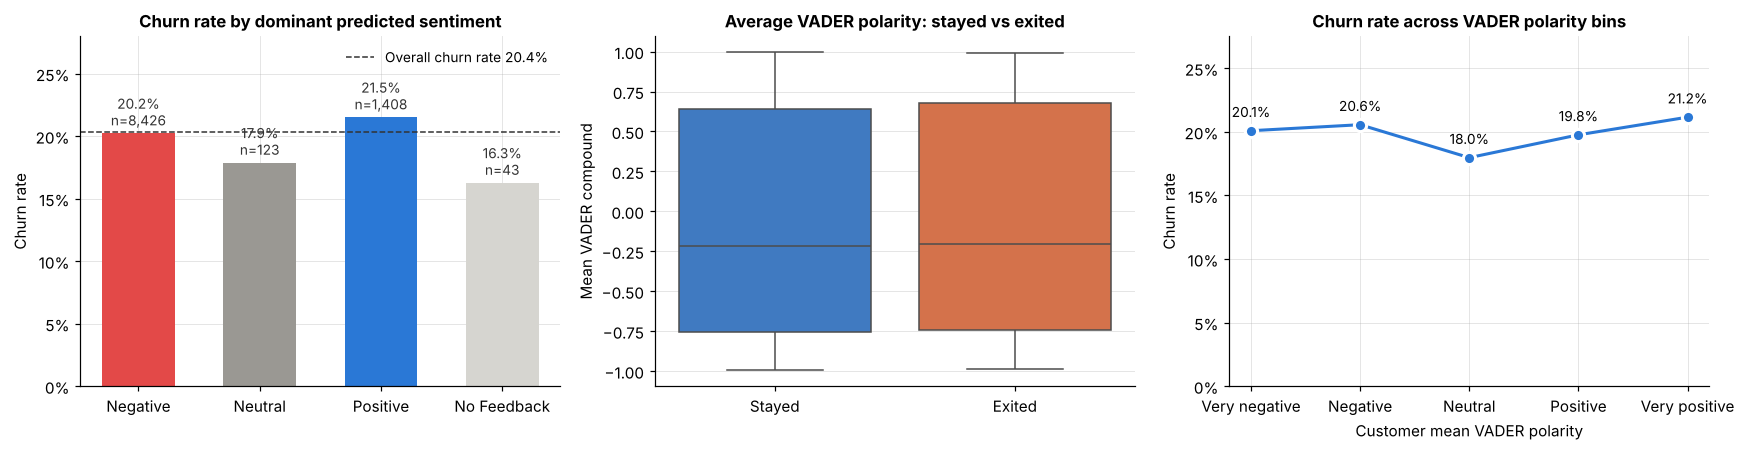

Chi-square test, dominant sentiment vs Exited (feedback customers): chi2=1.71, dof=2, p=4.26e-01


In [37]:
overall_rate = unified[TARGET].mean()
order = [c for c in SENT_ORDER + ["No Feedback"] if c in set(unified["dominant_predicted"])]
rate = unified.groupby("dominant_predicted")[TARGET].agg(["mean", "size"]).reindex(order)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
bars = axes[0].bar(rate.index, rate["mean"], color=[SENT_COLORS[c] for c in rate.index], width=0.6)
axes[0].bar_label(bars, labels=[f"{m:.1%}\nn={n:,}" for m, n in zip(rate["mean"], rate["size"])],
                  padding=3, fontsize=9, color="#333333")
axes[0].axhline(overall_rate, color="#333333", ls="--", lw=1, label=f"Overall churn rate {overall_rate:.1%}")
axes[0].legend(frameon=False, loc="upper right", fontsize=9)
axes[0].set(title="Churn rate by dominant predicted sentiment", ylabel="Churn rate",
            ylim=(0, rate["mean"].max() * 1.3))
axes[0].yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))

sns.boxplot(data=fb_customers, x=TARGET, y="vader_mean", hue=TARGET, palette=EXIT_COLORS,
            legend=False, fliersize=2, ax=axes[1])
axes[1].set_xticks([0, 1], [EXIT_NAMES[0], EXIT_NAMES[1]])
axes[1].set(title="Average VADER polarity: stayed vs exited", xlabel="", ylabel="Mean VADER compound")

bins = pd.cut(fb_customers["vader_mean"], bins=[-1.0001, -0.5, -0.05, 0.05, 0.5, 1.0001],
              labels=["Very negative", "Negative", "Neutral", "Positive", "Very positive"])
by_bin = fb_customers.groupby(bins, observed=True)[TARGET].agg(["mean", "size"])
axes[2].plot(by_bin.index.astype(str), by_bin["mean"], color="#2a78d6", lw=2, marker="o", ms=8,
             markeredgecolor="white", markeredgewidth=2)
for x_, (m, n) in enumerate(zip(by_bin["mean"], by_bin["size"])):
    axes[2].annotate(f"{m:.1%}", (x_, m), textcoords="offset points", xytext=(0, 9), ha="center", fontsize=9)
axes[2].set(title="Churn rate across VADER polarity bins", xlabel="Customer mean VADER polarity",
            ylabel="Churn rate", ylim=(0, by_bin["mean"].max() * 1.3))
axes[2].yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
fig.tight_layout()
savefig(fig, "t7_churn_by_sentiment")
plt.show()

ct = pd.crosstab(fb_customers["dominant_predicted"], fb_customers[TARGET])
chi2, p, dof, _ = stats.chi2_contingency(ct)
print(f"Chi-square test, dominant sentiment vs Exited (feedback customers): chi2={chi2:.2f}, dof={dof}, p={p:.2e}")

### 7.5 Key numbers for the write-up

In [38]:
best_overall = all_results.iloc[0]
rates = unified.groupby("dominant_predicted")[TARGET].mean()
summary = {
    "Feedback rows analyzed": f"{len(fb):,}",
    "Label source": LABEL_SOURCE_USED,
    "Label mix (Neg / Neu / Pos)": " / ".join(
        f"{fb['sentiment'].eq(c).mean():.0%}" for c in SENT_ORDER),
    "Best sentiment model": f"{best_overall['model']} + {best_overall['features']} "
                            f"(macro F1 {best_overall['f1_macro']:.3f}, accuracy {best_overall['accuracy']:.3f})",
    "Churn rate, Negative customers": f"{rates.get('Negative', np.nan):.1%}",
    "Churn rate, Positive customers": f"{rates.get('Positive', np.nan):.1%}",
    "Churn rate, overall": f"{overall_rate:.1%}",
    "Strongest sentiment correlate of Exited": (
        f"{corr_table.iloc[0]['feature']} (r = {corr_table.iloc[0]['r_with_Exited']:.3f}, "
        f"p = {corr_table.iloc[0]['p_value']:.1e})" if len(corr_table) else "n/a"),
}
for (subset, model), row in lift.iterrows():
    summary[f"ROC-AUC gain, {model} ({subset.lower()})"] = f"{row['roc_auc_gain']:+.4f}"
display(pd.Series(summary, name="value").to_frame())

,value
Feedback rows analyzed,"19,181"
Label source,rating
Label mix (Neg / Neu / Pos),89% / 2% / 10%
Best sentiment model,"Logistic Regression + TF-IDF (macro F1 0.668, ..."
"Churn rate, Negative customers",20.2%
"Churn rate, Positive customers",21.5%
"Churn rate, overall",20.4%
Strongest sentiment correlate of Exited,"pos_share (r = 0.011, p = 2.6e-01)"
"ROC-AUC gain, Logistic Regression (all customers)",-0.0010
"ROC-AUC gain, Gradient Boosting (all customers)",+0.0013


### Business insights

_Write these after running, using the numbers above. Prompts:_

1. **How customers feel:** What share of feedback is negative, and what themes dominate the negative word cloud (fees, wait times, app problems, staff)? These are the dissatisfaction patterns to act on.
2. **Sentiment and churn:** Does churn differ between negative, neutral, and positive customers? Check the correlation p-values and the chi-square test before claiming a relationship. A flat churn rate across sentiment groups is a legitimate finding and should be reported as one.
3. **Does NLP improve the churn model?** Report the ROC-AUC and F1 change from adding sentiment. A gain near zero (within the fold-to-fold standard deviation) means sentiment adds no predictive value on this data, which is worth stating plainly along with likely reasons.
4. **Classical vs deep learning:** Which sentiment model would you deploy and why (accuracy, speed, interpretability)?
5. **Recommendations:** for example, route customers with negative recent feedback to a retention team, monitor negative-share as a leading indicator, and fix the top recurring complaint themes.
6. **Limitations:** label quality (ratings vs lexicons), class balance (how small is the Neutral class?), feedback coverage (customers with no feedback), timing of feedback relative to churn, any repeated or templated text found in Task 4, and whether the feedback really belongs to these customers. Compare what the feedback file says about a customer (location, bank named in the text) with the churn file (`Geography`); if they disagree, the two datasets were joined synthetically and no real sentiment-churn link can be expected.